In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, ConcatDataset, random_split

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Hyperparameters
BATCH_SIZE = 128
LEARNING_RATE = 0.001
EPOCHS = 30
LATENT_DIM = 64

print("Device:", device)
print("Latent Dimension:", LATENT_DIM)

Device: cuda
Latent Dimension: 64


In [ ]:
import sys
import os

sys.path.append(os.path.abspath(".."))

from models.vae import VariationalAutoencoder

In [3]:
model = VariationalAutoencoder(
    latent_dim=LATENT_DIM
).to(device)

optimizer = optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

print(model)

VariationalAutoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
  )
  (fc_mu): Linear(in_features=256, out_features=64, bias=True)
  (fc_logvar): Linear(in_features=256, out_features=64, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=64, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=784, bias=True)
    (3): Sigmoid()
  )
)


In [4]:
def vae_loss(reconstructed, original, mu, logvar):

    # Reconstruction Loss
    recon_loss = F.mse_loss(
        reconstructed,
        original,
        reduction="sum"
    ) / original.size(0)

    # KL Divergence
    kl_loss = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp()
    ) / original.size(0)

    # Total Loss
    total_loss = recon_loss + kl_loss

    return total_loss, recon_loss, kl_loss

In [5]:
transform = transforms.ToTensor()

original_train = datasets.FashionMNIST(
    root="../data",
    train=True,
    download=True,
    transform=transform
)

original_test = datasets.FashionMNIST(
    root="../data",
    train=False,
    download=True,
    transform=transform
)

full_dataset = ConcatDataset([
    original_train,
    original_test
])

total_size = len(full_dataset)

train_size = int(0.8 * total_size)
val_size = int(0.1 * total_size)
test_size = total_size - train_size - val_size

generator = torch.Generator().manual_seed(42)

train_dataset, val_dataset, test_dataset = random_split(
    full_dataset,
    [train_size, val_size, test_size],
    generator=generator
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Testing:", len(test_dataset))

Training: 56000
Validation: 7000
Testing: 7000


In [6]:
def train_vae(model, train_loader, val_loader, epochs):

    train_losses = []
    val_losses = []

    train_recon_losses = []
    train_kl_losses = []

    for epoch in range(epochs):

        # Training
        model.train()

        running_total = 0.0
        running_recon = 0.0
        running_kl = 0.0

        for images, _ in train_loader:
            images = images.to(device)

            optimizer.zero_grad()

            reconstructed, mu, logvar = model(images)

            total_loss, recon_loss, kl_loss = vae_loss(
                reconstructed, images, mu, logvar
            )

            total_loss.backward()
            optimizer.step()

            running_total += total_loss.item()
            running_recon += recon_loss.item()
            running_kl += kl_loss.item()

        train_loss = running_total / len(train_loader)
        train_recon = running_recon / len(train_loader)
        train_kl = running_kl / len(train_loader)

        train_losses.append(train_loss)
        train_recon_losses.append(train_recon)
        train_kl_losses.append(train_kl)

        # Validation
        model.eval()
        val_total = 0.0

        with torch.no_grad():
            for images, _ in val_loader:
                images = images.to(device)

                reconstructed, mu, logvar = model(images)

                total_loss, _, _ = vae_loss(
                    reconstructed, images, mu, logvar
                )

                val_total += total_loss.item()

        val_loss = val_total / len(val_loader)
        val_losses.append(val_loss)

        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Train Loss: {train_loss:.4f} "
            f"Recon: {train_recon:.4f} "
            f"KL: {train_kl:.4f} "
            f"Val Loss: {val_loss:.4f}"
        )

    return (
        train_losses,
        val_losses,
        train_recon_losses,
        train_kl_losses
    )

In [7]:
train_losses, val_losses, train_recon_losses, train_kl_losses = train_vae(
    model,
    train_loader,
    val_loader,
    EPOCHS
)

Epoch [1/30] Train Loss: 45.5255 Recon: 39.0815 KL: 6.4440 Val Loss: 36.5139
Epoch [2/30] Train Loss: 33.9996 Recon: 25.9607 KL: 8.0389 Val Loss: 31.6353
Epoch [3/30] Train Loss: 29.9795 Recon: 22.5271 KL: 7.4525 Val Loss: 29.5554
Epoch [4/30] Train Loss: 28.3122 Recon: 20.9783 KL: 7.3339 Val Loss: 27.9340
Epoch [5/30] Train Loss: 27.4612 Recon: 20.0541 KL: 7.4072 Val Loss: 27.3978
Epoch [6/30] Train Loss: 26.9150 Recon: 19.4244 KL: 7.4906 Val Loss: 26.9342
Epoch [7/30] Train Loss: 26.5755 Recon: 18.9955 KL: 7.5800 Val Loss: 26.5138
Epoch [8/30] Train Loss: 26.2283 Recon: 18.5872 KL: 7.6411 Val Loss: 26.2850
Epoch [9/30] Train Loss: 25.9523 Recon: 18.2740 KL: 7.6782 Val Loss: 26.0073
Epoch [10/30] Train Loss: 25.7425 Recon: 18.0032 KL: 7.7393 Val Loss: 25.8162
Epoch [11/30] Train Loss: 25.5579 Recon: 17.7797 KL: 7.7782 Val Loss: 25.7032
Epoch [12/30] Train Loss: 25.3800 Recon: 17.5854 KL: 7.7947 Val Loss: 25.5663
Epoch [13/30] Train Loss: 25.2540 Recon: 17.4234 KL: 7.8306 Val Loss: 25.

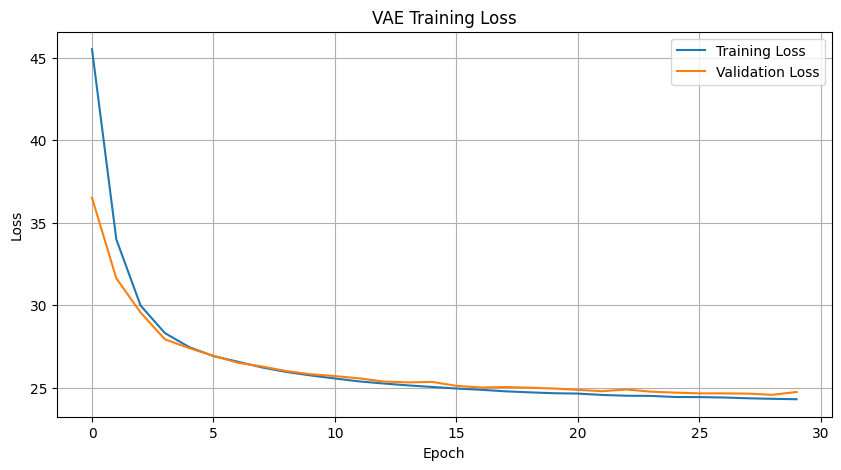

In [9]:
plt.figure(figsize=(10, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("VAE Training Loss")

plt.legend()
plt.grid(True)
plt.show()

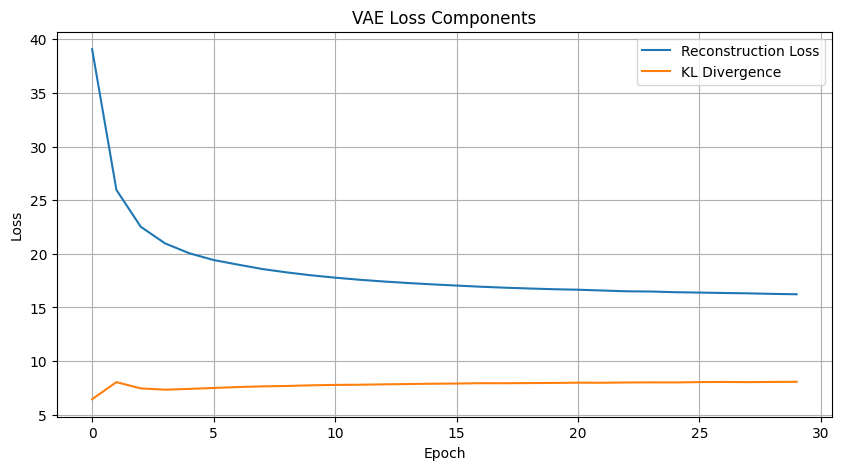

In [10]:
plt.figure(figsize=(10, 5))

plt.plot(train_recon_losses, label="Reconstruction Loss")
plt.plot(train_kl_losses, label="KL Divergence")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("VAE Loss Components")

plt.legend()
plt.grid(True)
plt.show()

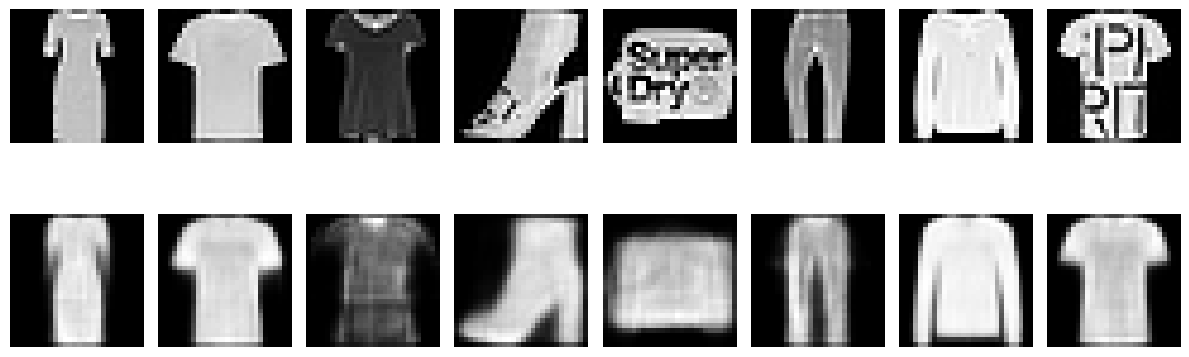

In [11]:
model.eval()

images, labels = next(iter(test_loader))
images = images.to(device)

with torch.no_grad():
    reconstructed, mu, logvar = model(images)

plt.figure(figsize=(12, 5))

for i in range(8):
    # Original
    plt.subplot(2, 8, i + 1)
    plt.imshow(images[i].cpu().squeeze(), cmap="gray")
    plt.axis("off")

    if i == 0:
        plt.ylabel("Original")

    # Reconstructed
    plt.subplot(2, 8, i + 9)
    plt.imshow(reconstructed[i].cpu().squeeze(), cmap="gray")
    plt.axis("off")

    if i == 0:
        plt.ylabel("VAE")

plt.tight_layout()
plt.show()

In [14]:
from skimage.metrics import structural_similarity as ssim
from skimage.metrics import peak_signal_noise_ratio as psnr

model.eval()

mse_total = 0
psnr_total = 0
ssim_total = 0
total_images = 0

with torch.no_grad():
    for images, _ in test_loader:
        images = images.to(device)

        reconstructed, mu, logvar = model(images)

        original_np = images.cpu().numpy()
        reconstructed_np = reconstructed.cpu().numpy()

        for i in range(len(images)):
            original = original_np[i].squeeze()
            generated = reconstructed_np[i].squeeze()

            mse_total += np.mean((original - generated) ** 2)

            psnr_total += psnr(
                original, generated, data_range=1.0
            )

            ssim_total += ssim(
                original, generated, data_range=1.0
            )

            total_images += 1

print("MSE:", mse_total / total_images)
print("PSNR:", psnr_total / total_images)
print("SSIM:", ssim_total / total_images)

MSE: 0.021821955463516392
PSNR: 17.12625418210656
SSIM: 0.5976210076623519


In [15]:
import json
import os

os.makedirs("../results/checkpoints", exist_ok=True)
os.makedirs("../results/metrics", exist_ok=True)

# Save model
torch.save(
    model.state_dict(),
    "../results/checkpoints/vae.pth"
)

# Save metrics
vae_metrics = {
    "MSE": 0.021821955463516392,
    "PSNR": 17.12625418210656,
    "SSIM": 0.5976210076623519
}

with open("../results/metrics/vae_metrics.json", "w") as f:
    json.dump(vae_metrics, f, indent=4)

print("VAE checkpoint and metrics saved!")

VAE checkpoint and metrics saved!


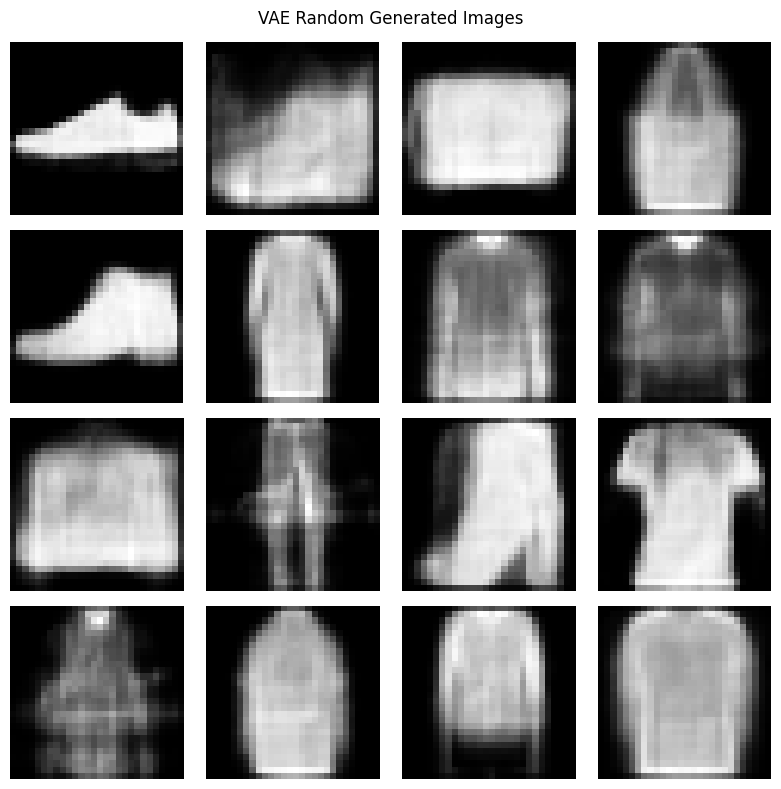

In [16]:
model.eval()

with torch.no_grad():
    z = torch.randn(16, LATENT_DIM).to(device)

    generated_images = model.decoder(z)

generated_images = generated_images.cpu().view(-1, 1, 28, 28)

plt.figure(figsize=(8, 8))

for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(generated_images[i].squeeze(), cmap="gray")
    plt.axis("off")

plt.suptitle("VAE Random Generated Images")
plt.tight_layout()
plt.show()

In [17]:
import os
from torchvision.utils import save_image

os.makedirs("../results/generated_images", exist_ok=True)

save_image(
    generated_images,
    "../results/generated_images/vae_generated.png",
    nrow=4
)

print("Generated images saved!")

Generated images saved!


In [18]:
torch.save(
    model.state_dict(),
    "../results/checkpoints/vae.pth"
)

print("VAE checkpoint saved!")

VAE checkpoint saved!
